In [1]:
import kagglehub, os, glob
import cv2, numpy as np
import matplotlib.pyplot as plt
import pandas as pd

path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")

files = sorted(glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True))
print(len(files))

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
20030


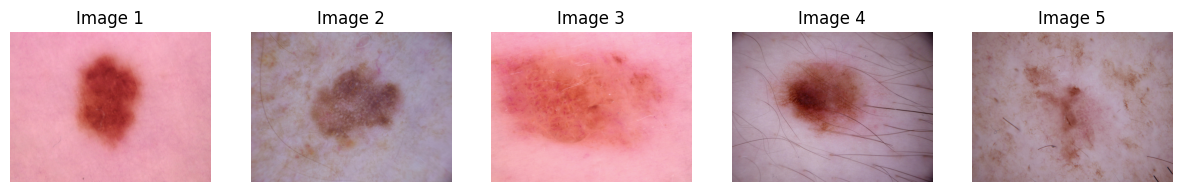

In [2]:
np.random.seed(1)
selected = list(np.random.choice(files, 5, replace=False))
images = [cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB) for f in selected]

plt.figure(figsize=(15, 3))
for i, img in enumerate(images):
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Image {i+1}")
    plt.axis("off")
plt.show()

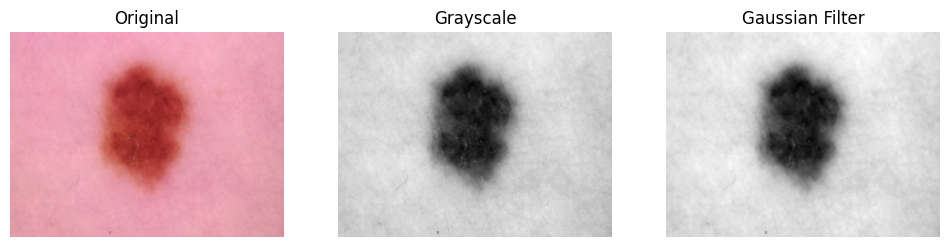

In [3]:
grays = [cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) for img in images]
blurs = [cv2.GaussianBlur(g, (5, 5), 0) for g in grays]

img_no = 0
plt.figure(figsize=(12, 4))
for i, (t, im) in enumerate([("Original", images[img_no]), ("Grayscale", grays[img_no]), ("Gaussian Filter", blurs[img_no])]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im, cmap=None if i == 0 else "gray")
    plt.title(t)
    plt.axis("off")
plt.show()

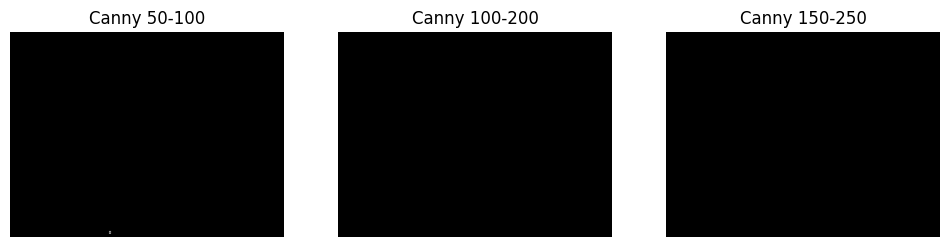

In [4]:
thresholds = [(50, 100), (100, 200), (150, 250)]

plt.figure(figsize=(12, 4))
for i, (lo, hi) in enumerate(thresholds):
    edges = cv2.Canny(blurs[img_no], lo, hi)
    plt.subplot(1, 3, i + 1)
    plt.imshow(edges, cmap="gray")
    plt.title(f"Canny {lo}-{hi}")
    plt.axis("off")
plt.show()

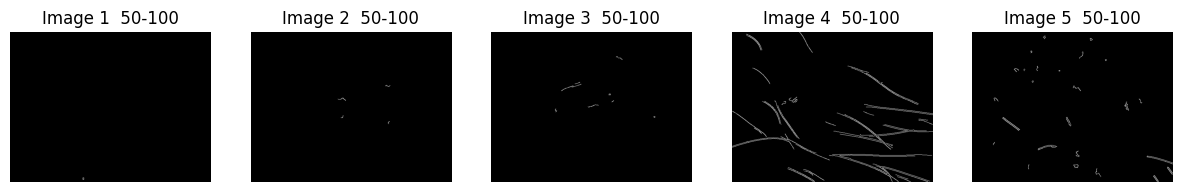

In [5]:
best = (50, 100)  # change after viewing the edge maps above

plt.figure(figsize=(15, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(cv2.Canny(blurs[i], *best), cmap="gray")
    plt.title(f"Image {i+1}  {best[0]}-{best[1]}")
    plt.axis("off")
plt.show()

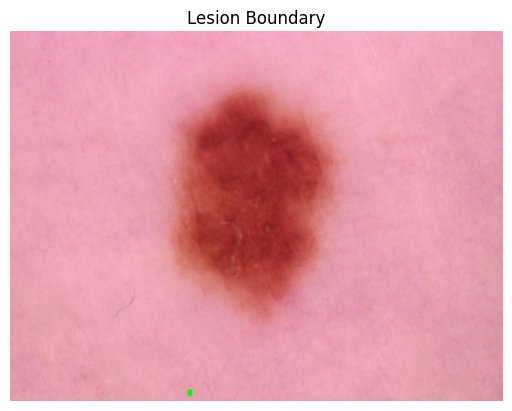

In [6]:
def detect_boundary(img, blur, th):
    edges = cv2.Canny(blur, *th)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=2)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnt = max(contours, key=cv2.contourArea)
    out = img.copy()
    cv2.drawContours(out, [cnt], -1, (0, 255, 0), 2)
    return edges, cnt, out

edges, cnt, out = detect_boundary(images[img_no], blurs[img_no], best)
plt.imshow(out)
plt.title("Lesion Boundary")
plt.axis("off")
plt.show()

In [7]:
mask = np.zeros(grays[img_no].shape, np.uint8)
cv2.drawContours(mask, [cnt], -1, 255, -1)

print("Area (pixels):", cv2.countNonZero(mask))
print("Perimeter (pixels):", round(cv2.arcLength(cnt, True), 2))

Area (pixels): 24
Perimeter (pixels): 16.0


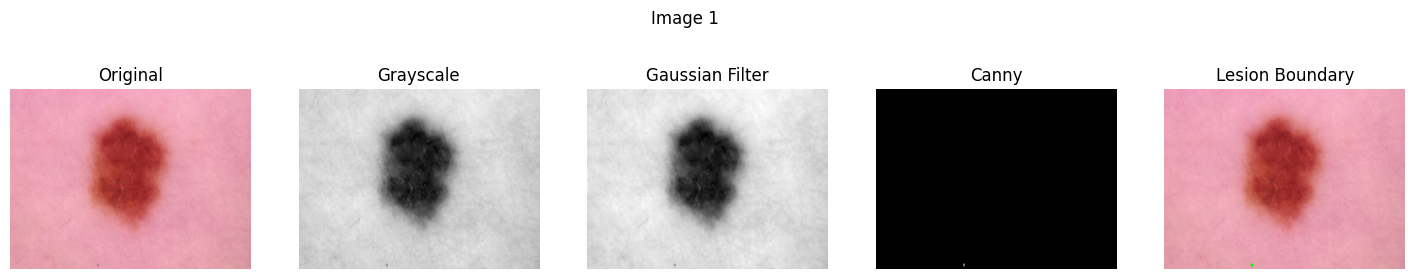

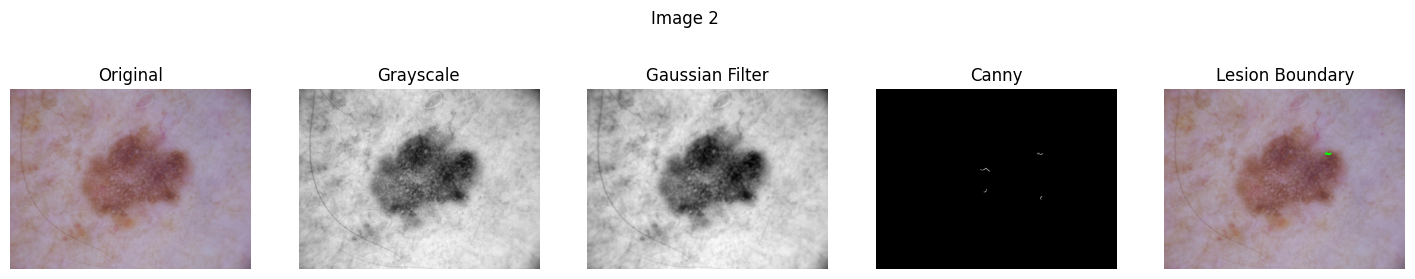

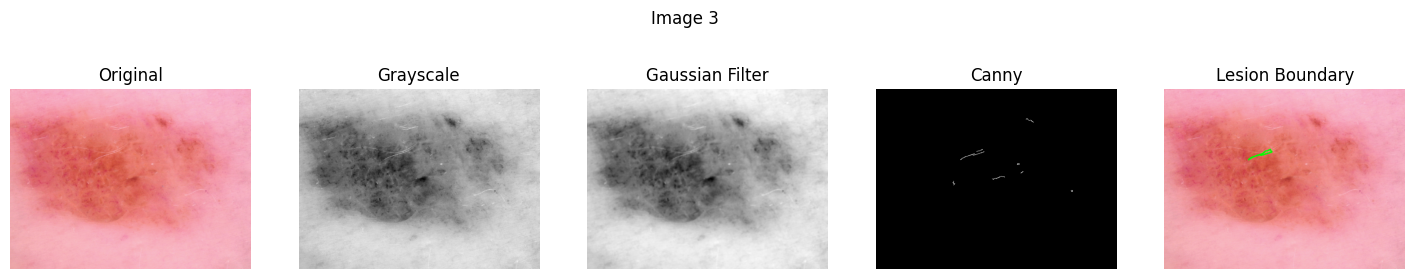

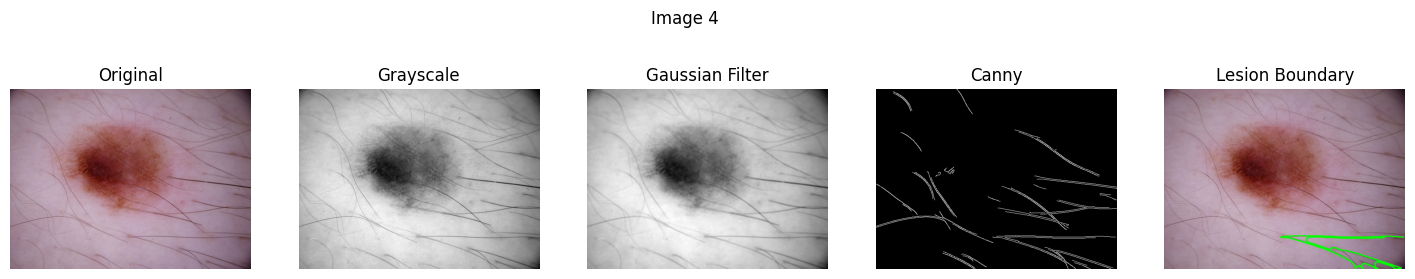

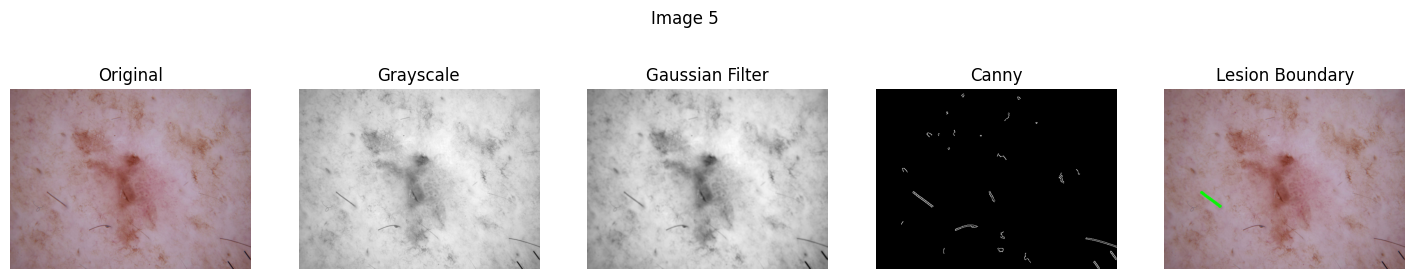

,Image,Best Filter,Edge Method,Area (pixels),Perimeter (pixels)
0,Image 1,Gaussian,Canny 50-100,15,16.00
1,Image 2,Gaussian,Canny 50-100,20,33.80
2,Image 3,Gaussian,Canny 50-100,163,144.12
3,Image 4,Gaussian,Canny 50-100,3870,1243.65
4,Image 5,Gaussian,Canny 50-100,240,136.07


In [8]:
rows = []
for i in range(5):
    edges, cnt, out = detect_boundary(images[i], blurs[i], best)

    plt.figure(figsize=(18, 3.5))
    for j, (t, im, cm) in enumerate([("Original", images[i], None), ("Grayscale", grays[i], "gray"),
                                      ("Gaussian Filter", blurs[i], "gray"), ("Canny", edges, "gray"),
                                      ("Lesion Boundary", out, None)]):
        plt.subplot(1, 5, j + 1)
        plt.imshow(im, cmap=cm)
        plt.title(t)
        plt.axis("off")
    plt.suptitle(f"Image {i+1}")
    plt.show()

    rows.append({"Image": f"Image {i+1}", "Best Filter": "Gaussian", "Edge Method": f"Canny {best[0]}-{best[1]}",
                 "Area (pixels)": int(cv2.contourArea(cnt)), "Perimeter (pixels)": round(cv2.arcLength(cnt, True), 2)})

pd.DataFrame(rows)

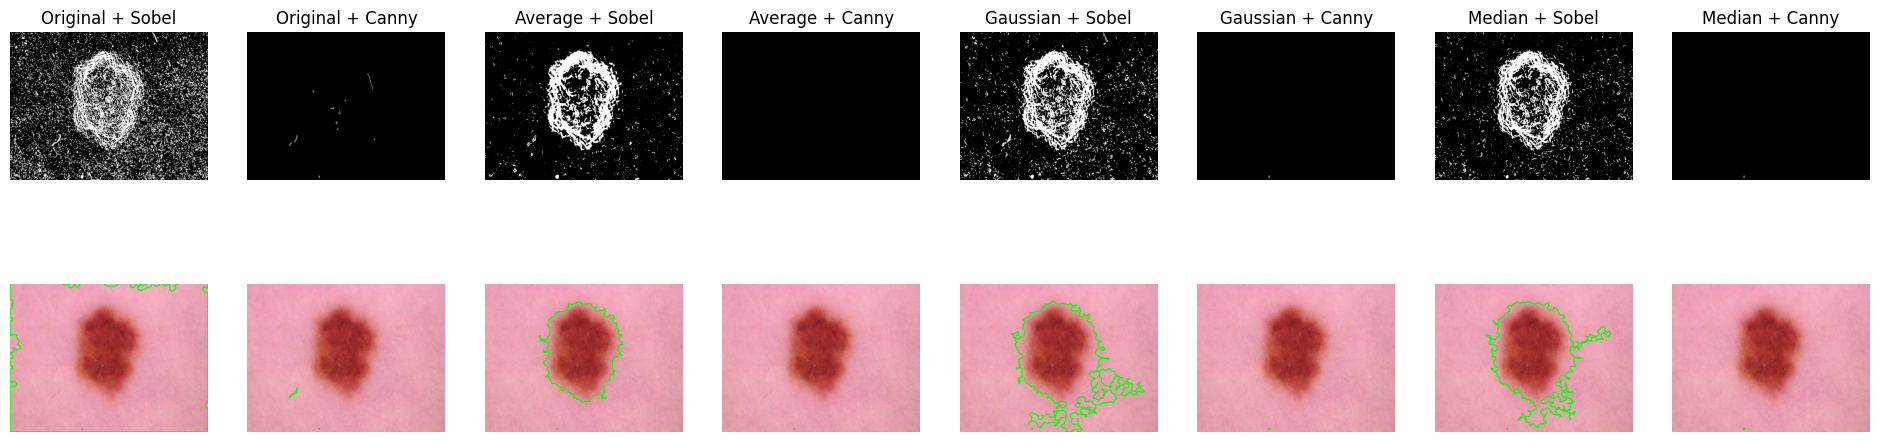

,Method,Edge Pixels (noise indicator),Area,Perimeter
0,Original + Sobel,67932,264599,2567.36
1,Original + Canny,246,87,93.98
2,Average + Sobel,32845,50754,1338.81
3,Average + Canny,0,0,0.00
4,Gaussian + Sobel,41115,69219,3769.20
5,Gaussian + Canny,16,15,16.00
6,Median + Sobel,36122,62047,3172.02
7,Median + Canny,17,18,17.66


In [9]:
def sobel_edges(g):
    sx = cv2.Sobel(g, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(g, cv2.CV_64F, 0, 1, ksize=3)
    mag = cv2.magnitude(sx, sy)
    mag = cv2.convertScaleAbs(mag)
    _, e = cv2.threshold(mag, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return e

filters = {
    "Original": lambda g: g,
    "Average": lambda g: cv2.blur(g, (5, 5)),
    "Gaussian": lambda g: cv2.GaussianBlur(g, (5, 5), 0),
    "Median": lambda g: cv2.medianBlur(g, 5),
}
edge_methods = {"Sobel": sobel_edges, "Canny": lambda g: cv2.Canny(g, *best)}

def largest_boundary(edges):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=2)
    cs, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return max(cs, key=cv2.contourArea) if cs else None

g = grays[img_no]
fig, axs = plt.subplots(2, 8, figsize=(24, 6))
results = []
col = 0
for fname, f in filters.items():
    for ename, e in edge_methods.items():
        filtered = f(g)
        edges = e(filtered)
        c = largest_boundary(edges)
        out = images[img_no].copy()
        area = per = 0
        if c is not None:
            cv2.drawContours(out, [c], -1, (0, 255, 0), 2)
            area, per = cv2.contourArea(c), cv2.arcLength(c, True)
        axs[0, col].imshow(edges, cmap="gray"); axs[0, col].set_title(f"{fname} + {ename}")
        axs[1, col].imshow(out)
        axs[0, col].axis("off"); axs[1, col].axis("off")
        edge_pixels = cv2.countNonZero(edges)
        results.append({"Method": f"{fname} + {ename}", "Edge Pixels (noise indicator)": edge_pixels,
                        "Area": int(area), "Perimeter": round(per, 2)})
        col += 1
plt.show()

pd.DataFrame(results)